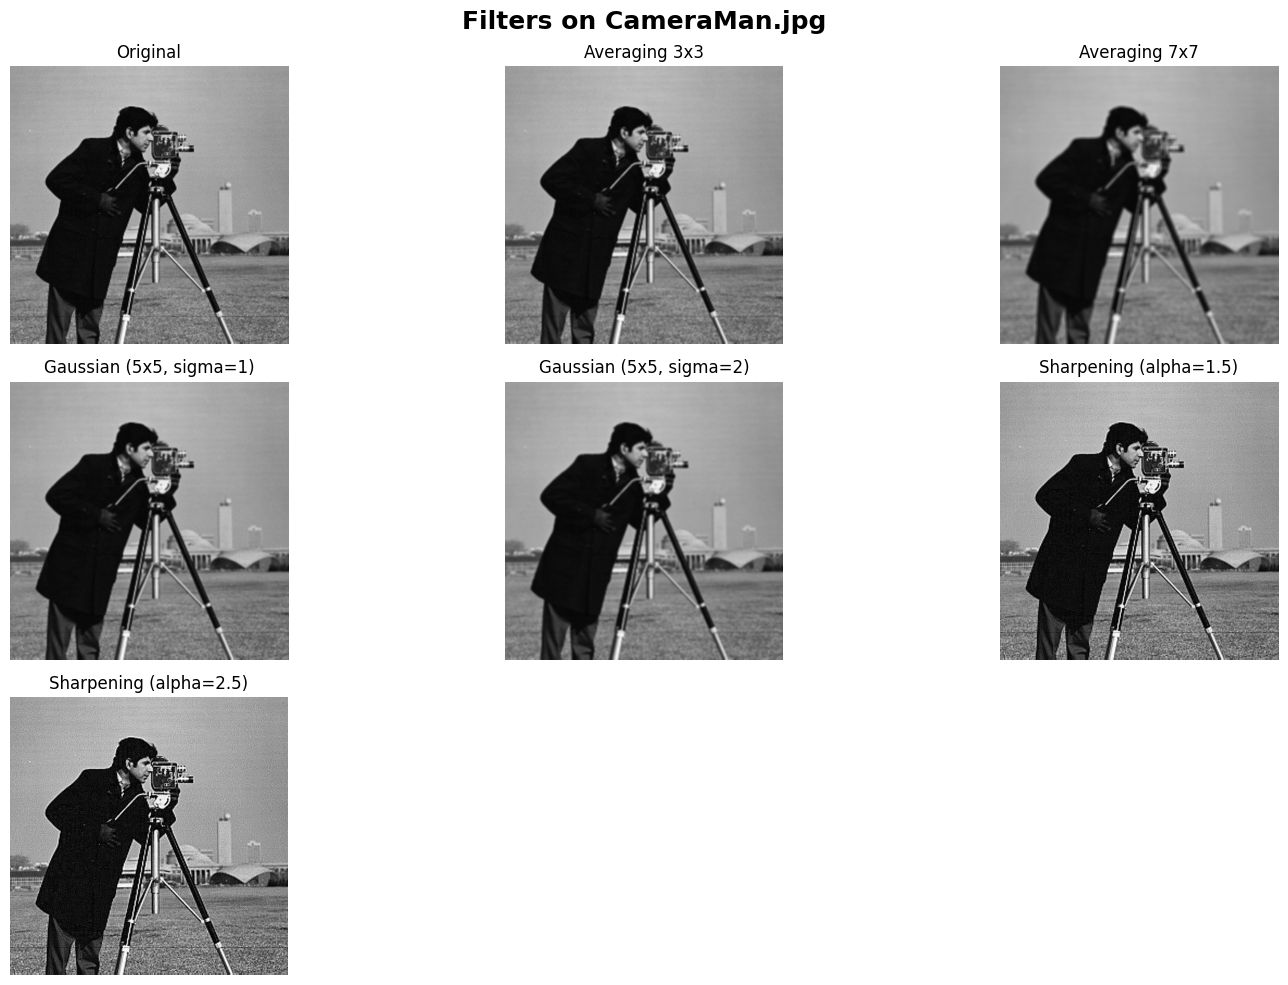

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Grayscale
img = cv.imread('CameraMan.jpg', cv.IMREAD_GRAYSCALE)
assert img is not None, "CameraMan.jpg not found"

results = []
titles  = []

# avg filter
avg_3x3 = cv.blur(img, (3, 3))
avg_7x7 = cv.blur(img, (7, 7))

results.extend([img, avg_3x3, avg_7x7])
titles.extend(['Original', 'Averaging 3x3', 'Averaging 7x7'])

# gaussian filter
gauss_5x5_s1 = cv.GaussianBlur(img, (5,5), sigmaX=1)
gauss_5x5_s0 = cv.GaussianBlur(img, (5,5), sigmaX=2)

results.extend([gauss_5x5_s1, gauss_5x5_s0])
titles.extend(['Gaussian (5x5, sigma=1)', 'Gaussian (5x5, sigma=2)'])

# original + alpha * (original - blurred)
def sharpen(image, kernel_size=(5,5), sigma=1.0, alpha=1.0):
    blurred = cv.GaussianBlur(image, kernel_size, sigma)
    return cv.addWeighted(image, 1.0 + alpha, blurred, -alpha, 0) # this means: (1 + alpha) * original - alpha * blur, expand the sharpening formula and it pops out

sharpened_1_5 = sharpen(img, kernel_size=(5,5), sigma=1.0, alpha=1.5)
sharpened_2_5 = sharpen(img, kernel_size=(5,5), sigma=1.0, alpha=2.5)

results.extend([sharpened_1_5, sharpened_2_5])
titles.extend(['Sharpening (alpha=1.5)', 'Sharpening (alpha=2.5)'])

plt.figure(figsize=(15, 10))

for i in range(len(results)):
    plt.subplot(3, 3, i+1)
    plt.imshow(results[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=12)
    plt.axis('off')

plt.suptitle('Filters on CameraMan.jpg', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()